# Figure 1 — plate heatmaps of LSPR peak wavelength

Reads `plate_spectra.xlsx` (one tab per run, absorbance only), computes the peak
wavelength for every well, and draws all five plates as a single row of heatmaps
sharing **one universal colorbar**.

## 1. Settings

In [1]:
DATA_FILE = "plate_spectra.xlsx"   # path to the spectra workbook

# Peak-search window (nm). The maximum absorbance is located inside this window.
WIN_LO, WIN_HI = 500, 900

CMAP  = "turbo"     # colormap shared by every panel
TICK_STEP = 50      # colorbar tick spacing, nm

# Set these to override the automatic scale, e.g. VMIN, VMAX = 500, 900
VMIN = VMAX = None

SAVE_AS = "Figure1_heatmaps"      # writes .pdf and .png; set to None to skip
DPI = 400

## 2. Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# use Arial if installed, else the closest metric-compatible fallback
from matplotlib import font_manager
_installed = {f.name for f in font_manager.fontManager.ttflist}
mpl.rcParams["font.family"] = next(
    (f for f in ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"] if f in _installed),
    "sans-serif")

mpl.rcParams["pdf.fonttype"] = 42   
mpl.rcParams["svg.fonttype"] = "none"

PLATE_ROWS = list("ABCDEFGH")
PLATE_COLS = list(range(1, 13))

## 3. Load the tabs


In [3]:
xls = pd.ExcelFile(DATA_FILE)

run_names = sorted(
    [s for s in xls.sheet_names if s.strip().lower().startswith("run")],
    key=lambda s: int("".join(ch for ch in s if ch.isdigit()))
)

spectra = {r: pd.read_excel(xls, sheet_name=r, index_col=0) for r in run_names}

for r, df in spectra.items():
    print(f"{r}: {df.shape[0]} wavelengths ({df.index.min():.0f}-{df.index.max():.0f} nm), "
          f"{df.shape[1]} wells")

Run 0: 325 wavelengths (350-998 nm), 96 wells
Run 1: 325 wavelengths (350-998 nm), 96 wells
Run 2: 325 wavelengths (350-998 nm), 96 wells
Run 3: 325 wavelengths (350-998 nm), 96 wells
Run 4: 350 wavelengths (300-998 nm), 96 wells


## 4. Peak wavelength per well

`lambda_max` is the wavelength of maximum absorbance inside the search window.

A well that returns exactly `WIN_LO` has **no** maximum inside the window — its
spectrum falls monotonically from the lower edge. Those are blank / no-LSPR wells
rather than a measured 500 nm peak, and they are counted separately below.

In [4]:
def lambda_max_grid(df, lo=WIN_LO, hi=WIN_HI):
    """Return an 8x12 array of peak wavelengths laid out as the physical plate."""
    sub = df.loc[(df.index >= lo) & (df.index <= hi)]
    peak = sub.idxmax(axis=0)
    return np.array([[peak[f"{r}{c}"] for c in PLATE_COLS] for r in PLATE_ROWS],
                    dtype=float)

grids = {r: lambda_max_grid(df) for r, df in spectra.items()}

summary = pd.DataFrame({
    "min (nm)":     {r: g.min() for r, g in grids.items()},
    "max (nm)":     {r: g.max() for r, g in grids.items()},
    "median (nm)":  {r: np.median(g) for r, g in grids.items()},
    "no peak (=%d)" % WIN_LO: {r: int((g == WIN_LO).sum()) for r, g in grids.items()},
})
summary

,min (nm),max (nm),median (nm),no peak (=500)
Run 0,500.0,876.0,553.0,38
Run 1,500.0,820.0,710.0,24
Run 2,500.0,876.0,688.0,16
Run 3,500.0,900.0,872.0,29
Run 4,500.0,838.0,720.0,24


## 5. The universal colour scale

Limits are rounded outward to the nearest tick so the bar ends on a labelled value,
and an assertion confirms no well falls outside the scale

In [5]:
pooled = np.concatenate([g.ravel() for g in grids.values()])

vmin = VMIN if VMIN is not None else np.floor(pooled.min() / TICK_STEP) * TICK_STEP
vmax = VMAX if VMAX is not None else np.ceil(pooled.max() / TICK_STEP) * TICK_STEP

norm = Normalize(vmin=vmin, vmax=vmax)          
cmap = plt.get_cmap(CMAP)
ticks = np.arange(vmin, vmax + 1, TICK_STEP)

n_clipped = int(((pooled < vmin) | (pooled > vmax)).sum())
assert n_clipped == 0, f"{n_clipped} wells fall outside the colour scale and would be clipped"

print(f"data range {pooled.min():.0f}-{pooled.max():.0f} nm  ->  "
      f"colour scale {vmin:.0f}-{vmax:.0f} nm, no wells clipped")

data range 500-900 nm  ->  colour scale 500-900 nm, no wells clipped


## 6. Draw the figure


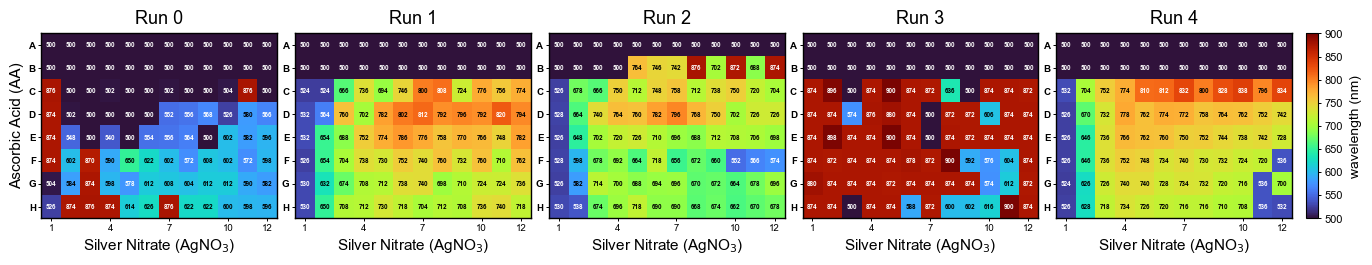

In [6]:
def label_colour(value):
    """Black or white annotation, whichever stays readable on this cell."""
    r, g, b, _ = cmap(norm(value))
    return "black" if 0.2126*r + 0.7152*g + 0.0722*b > 0.55 else "white"


def plot_row(grids, norm, cmap, ticks, cbar_label="wavelength (nm)"):
    n = len(grids)
    fig = plt.figure(figsize=(2.77 * n, 2.55))

    left, right, bottom, top = 0.032, 0.935, 0.175, 0.90
    gap = 0.013
    pw = (right - left - gap * (n - 1)) / n      

    for i, (name, g) in enumerate(grids.items()):
        ax = fig.add_axes([left + i * (pw + gap), bottom, pw, top - bottom])
        ax.imshow(g, cmap=cmap, norm=norm, aspect="auto", interpolation="nearest")

        for r in range(g.shape[0]):
            for cc in range(g.shape[1]):
                v = g[r, cc]
                ax.text(cc, r, f"{v:.0f}", ha="center", va="center",
                        fontsize=4.6, fontweight="bold", color=label_colour(v))

        ax.set_title(name, fontsize=13, pad=7)
        ax.set_xticks([0, 3, 6, 9, 11])
        ax.set_xticklabels([1, 4, 7, 10, 12], fontsize=7)
        ax.set_yticks(range(len(PLATE_ROWS)))
        ax.set_yticklabels(PLATE_ROWS, fontsize=7, fontweight="bold")
        ax.tick_params(length=2.5, width=0.7, pad=1.5)
        ax.set_xlabel("Silver Nitrate (AgNO$_3$)", fontsize=11, labelpad=3)
        if i == 0:
            ax.set_ylabel("Ascorbic Acid (AA)", fontsize=11, labelpad=3)
        for s in ax.spines.values():
            s.set_linewidth(1.0)

    # --- the single universal colorbar ---
    cax = fig.add_axes([right + 0.010, bottom, 0.009, top - bottom])
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax)
    cb.set_ticks(ticks)
    cb.ax.set_yticklabels([f"{t:.0f}" for t in ticks], fontsize=8)
    cb.set_label(cbar_label, fontsize=10, labelpad=5)
    cb.outline.set_linewidth(0.8)
    cb.ax.tick_params(length=2.5, width=0.7, pad=2)
    return fig


fig = plot_row(grids, norm, cmap, ticks)
plt.show()

## 7. Save

In [7]:
if SAVE_AS:
    fig.savefig(f"{SAVE_AS}.pdf")       
    fig.savefig(f"{SAVE_AS}.png", dpi=DPI)
    print(f"wrote {SAVE_AS}.pdf and {SAVE_AS}.png")

wrote Figure1_heatmaps.pdf and Figure1_heatmaps.png


---

# Figure 2 — one plate in detail

Four panels for a single run, all computed from the same tab of
`plate_spectra.xlsx`:

| panel | what it shows |
|---|---|
| **a** | $\lambda_{max}$ over the full window — the longitudinal band where one exists, otherwise whatever the transverse band or the baseline puts on top |
| **b** | $\lambda_{max}$ restricted to the longitudinal window. Wells whose value moved between a and b are outlined |
| **c** | longitudinal / transverse absorbance ratio, indicating how much of the extinction is rod-like rather than sphere-like |
| **d** | the underlying spectra for one row, with both search windows shaded |

Panels a and b share one colour scale

## 8. Figure 2 settings

In [8]:
FIG2_RUN = "Run 4"            # which tab Figure 2 describes

# The two spectral regions. A gold nanorod has a transverse band near 520 nm
# (short axis, roughly fixed) and a longitudinal band further red (long axis,
# moves with aspect ratio). Panel b and the ratio in panel c both rely on
# separating them.
TRANSVERSE   = (500, 580)
LONGITUDINAL = (600, 900)

RATIO_CMAP   = "RdBu_r"       # diverging: below 1 blue, above 1 red
RATIO_CENTER = 1.0            # ratio = 1 means the two bands are equal

# Panel d: which spectra to draw, and which to dash as flagged.
WATERFALL_WELLS = [f"H{c}" for c in range(1, 13)]
WATERFALL_DASHED = ["H11", "H12"]
WATERFALL_XLIM   = (420, 960)
WATERFALL_CMAP   = "viridis"

# Which cells get outlined in panel b:
#   "changed"   - every well whose lambda_max moved between the two windows
#   "real-swap" - only wells that actually have a longitudinal band (ratio >= 1),
#                 i.e. genuine band swaps, leaving the no-band wells unmarked
OUTLINE = "changed"

SAVE_AS_FIG2 = "Figure2_panels"    # writes .pdf and .png; None to skip

## 9. The two Figure 2 metrics

`lambda_max_grid` from section 4 is reused with different windows — panel a is
the full window, panel b the longitudinal one.

The ratio is peak absorbance in the longitudinal window divided by peak
absorbance in the transverse window. Above 1 the rod-like band dominates;
below 1 the well is mostly spheres, unreacted salt, or nothing at all.

In [9]:
def ratio_grid(df, trans=TRANSVERSE, longi=LONGITUDINAL):
    """Longitudinal / transverse peak absorbance, as an 8x12 plate array."""
    wl = df.index.values.astype(float)
    mT = (wl >= trans[0]) & (wl <= trans[1])
    mL = (wl >= longi[0]) & (wl <= longi[1])
    return np.array([[df[f"{r}{c}"].values[mL].max() / df[f"{r}{c}"].values[mT].max()
                      for c in PLATE_COLS] for r in PLATE_ROWS])


df2 = spectra[FIG2_RUN]

g_full = lambda_max_grid(df2, WIN_LO, WIN_HI)                  # panel a
g_long = lambda_max_grid(df2, LONGITUDINAL[0], LONGITUDINAL[1])  # panel b
g_ratio = ratio_grid(df2)                                       # panel c

moved = g_full != g_long
if OUTLINE == "real-swap":
    moved = moved & (ratio_grid(df2) >= RATIO_CENTER)

# one colour scale for panels a and b, built from both so neither is clipped
pooled2 = np.concatenate([g_full.ravel(), g_long.ravel()])
v2min = np.floor(pooled2.min() / TICK_STEP) * TICK_STEP
v2max = np.ceil(pooled2.max() / TICK_STEP) * TICK_STEP
norm2 = Normalize(vmin=v2min, vmax=v2max)
ticks2 = np.arange(v2min, v2max + 1, TICK_STEP)

assert not ((pooled2 < v2min) | (pooled2 > v2max)).any(), "panel a/b scale would clip"

print(f"{FIG2_RUN}: panels a+b share {v2min:.0f}-{v2max:.0f} nm; "
      f"{(g_full != g_long).sum()} of 96 wells change window to window, "
      f"{moved.sum()} outlined ({OUTLINE})")
print(f"ratio range {g_ratio.min():.2f}-{g_ratio.max():.2f}  "
      f"({(g_ratio >= 1).sum()} wells longitudinal-dominant)")

Run 4: panels a+b share 500-900 nm; 34 of 96 wells change window to window, 34 outlined (changed)
ratio range 0.33-2.93  (62 wells longitudinal-dominant)


## 10. Draw Figure 2

Panels a–c are annotated plate grids; panel d is the spectra behind them. The
outlines in panel b mark every well whose reported peak moved when the
transverse band was excluded — those are the wells where panel a was reporting
the wrong band.

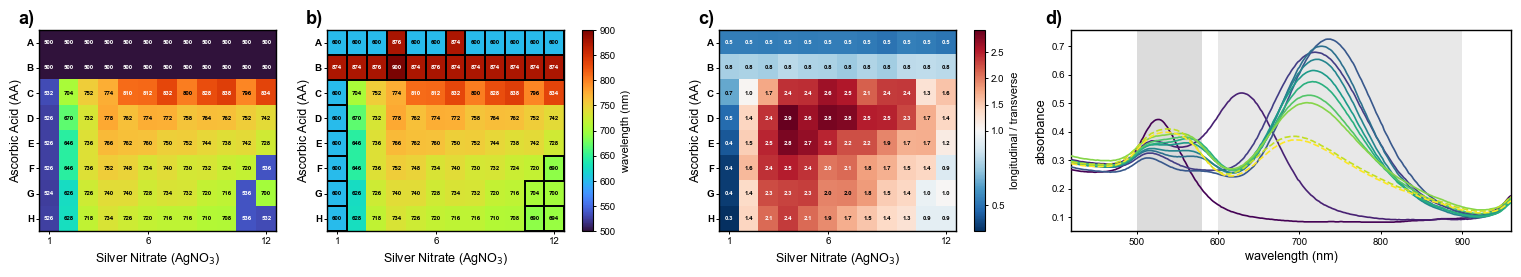

In [10]:
from matplotlib.patches import Rectangle
from matplotlib.colors import TwoSlopeNorm


def _plate_axes(ax, title_letter):
    ax.set_xticks([0, 5, 11]); ax.set_xticklabels([1, 6, 12], fontsize=7)
    ax.set_yticks(range(8)); ax.set_yticklabels(PLATE_ROWS, fontsize=7, fontweight="bold")
    ax.tick_params(length=2.5, width=0.7, pad=1.5)
    ax.set_xlabel("Silver Nitrate (AgNO$_3$)", fontsize=9, labelpad=3)
    for s in ax.spines.values():
        s.set_linewidth(1.0)
    ax.text(-0.02, 1.10, title_letter, transform=ax.transAxes,
            fontsize=13, fontweight="bold", va="top", ha="right")


def annotate(ax, grid, colour_fn, fmt="{:.0f}"):
    for r in range(grid.shape[0]):
        for c in range(grid.shape[1]):
            ax.text(c, r, fmt.format(grid[r, c]), ha="center", va="center",
                    fontsize=4.4, fontweight="bold", color=colour_fn(grid[r, c]))


def plot_figure2():
    fig = plt.figure(figsize=(16.0, 3.05))
    bottom, top = 0.20, 0.86
    h = top - bottom
    pw = 0.148                      # plate panel width
    x_a, x_b, x_c, x_d = 0.045, 0.225, 0.470, 0.690

    def lum_colour(norm_, cmap_):
        def f(v):
            r, g, b, _ = cmap_(norm_(v))
            return "black" if 0.2126*r + 0.7152*g + 0.0722*b > 0.55 else "white"
        return f

    # ---- a) full-window lambda_max ----
    ax = fig.add_axes([x_a, bottom, pw, h])
    ax.imshow(g_full, cmap=cmap, norm=norm2, aspect="auto", interpolation="nearest")
    annotate(ax, g_full, lum_colour(norm2, cmap))
    _plate_axes(ax, "a)")
    ax.set_ylabel("Ascorbic Acid (AA)", fontsize=9, labelpad=3)

    # ---- b) longitudinal-window lambda_max ----
    ax = fig.add_axes([x_b, bottom, pw, h])
    ax.imshow(g_long, cmap=cmap, norm=norm2, aspect="auto", interpolation="nearest")
    annotate(ax, g_long, lum_colour(norm2, cmap))
    for r, c in zip(*np.where(moved)):
        ax.add_patch(Rectangle((c-0.5, r-0.5), 1, 1, fill=False,
                               edgecolor="black", linewidth=1.4))
    _plate_axes(ax, "b)")
    ax.set_ylabel("Ascorbic Acid (AA)", fontsize=9, labelpad=3)

    cax = fig.add_axes([x_b + pw + 0.011, bottom, 0.007, h])
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm2, cmap=cmap), cax=cax)
    cb.set_ticks(ticks2); cb.ax.set_yticklabels([f"{t:.0f}" for t in ticks2], fontsize=7)
    cb.set_label("wavelength (nm)", fontsize=8, labelpad=4)
    cb.outline.set_linewidth(0.8); cb.ax.tick_params(length=2.5, width=0.7, pad=2)

    # ---- c) longitudinal / transverse ratio ----
    rnorm = TwoSlopeNorm(vmin=min(g_ratio.min(), RATIO_CENTER - 0.01),
                         vcenter=RATIO_CENTER, vmax=g_ratio.max())
    rcmap = plt.get_cmap(RATIO_CMAP)
    ax = fig.add_axes([x_c, bottom, pw, h])
    ax.imshow(g_ratio, cmap=rcmap, norm=rnorm, aspect="auto", interpolation="nearest")
    annotate(ax, g_ratio, lum_colour(rnorm, rcmap), fmt="{:.1f}")
    _plate_axes(ax, "c)")
    ax.set_ylabel("Ascorbic Acid (AA)", fontsize=9, labelpad=3)

    cax = fig.add_axes([x_c + pw + 0.011, bottom, 0.007, h])
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm=rnorm, cmap=rcmap), cax=cax)
    cb.ax.tick_params(labelsize=7, length=2.5, width=0.7, pad=2)
    cb.set_label("longitudinal / transverse", fontsize=8, labelpad=4)
    cb.outline.set_linewidth(0.8)

    # ---- d) the spectra behind them ----
    ax = fig.add_axes([x_d, bottom, 0.275, h])
    wl = df2.index.values.astype(float)
    m = (wl >= WATERFALL_XLIM[0]) & (wl <= WATERFALL_XLIM[1])
    wcmap = plt.get_cmap(WATERFALL_CMAP)
    n = len(WATERFALL_WELLS)

    ax.axvspan(*TRANSVERSE, color="0.55", alpha=0.30, lw=0, zorder=0)
    ax.axvspan(*LONGITUDINAL, color="0.80", alpha=0.45, lw=0, zorder=0)

    for i, well in enumerate(WATERFALL_WELLS):
        ax.plot(wl[m], df2[well].values[m],
                color=wcmap(i / max(n - 1, 1)), lw=1.2, zorder=3,
                linestyle="--" if well in WATERFALL_DASHED else "-")

    ax.set_xlim(*WATERFALL_XLIM)
    ax.set_xlabel("wavelength (nm)", fontsize=9, labelpad=3)
    ax.set_ylabel("absorbance", fontsize=9, labelpad=3)
    ax.tick_params(labelsize=7, length=2.5, width=0.7, pad=2)
    for s in ax.spines.values():
        s.set_linewidth(1.0)
    ax.text(-0.02, 1.10, "d)", transform=ax.transAxes,
            fontsize=13, fontweight="bold", va="top", ha="right")
    return fig


fig2 = plot_figure2()
plt.show()

## 11. Save Figure 2

In [12]:
if SAVE_AS_FIG2:
    fig2.savefig(f"{SAVE_AS_FIG2}.pdf")
    fig2.savefig(f"{SAVE_AS_FIG2}.png", dpi=DPI)
    print(f"wrote {SAVE_AS_FIG2}.pdf and {SAVE_AS_FIG2}.png")

wrote Figure2_panels.pdf and Figure2_panels.png


---

# Spectral roughness and signal-strength analysis (Appendix metric / Figure 3b)

This section computes **spectral roughness** and longitudinal-window absorbance directly from the `plate_spectra.xlsx` workbook used for Figures 1 and 2. **Run all preceding cells first** to load the `spectra` dictionary and imports.

- Use **rows C–H** (72 wells), with wavelengths **500–900 nm inclusive**.
- For each well, subtract its minimum absorbance within that window and divide the resulting spectrum by its $L_2$ norm.
- Interpolate each interior spectrum independently from its immediate left/right AgNO$_3$ neighbors and its immediate upper/lower AA neighbors, using the **actual nonuniform AgNO$_3$ dispensing coordinates** and AA concentrations.
- Compare the root-mean-squared interpolation residual, $E_{\mathrm{interp}}$ (**108 residual spectra**: 60 along AgNO$_3$, 48 along AA), against the root-mean-squared difference between adjacent spectra, $E_{\mathrm{nn}}$ (**126 pairs**: 66 along AgNO$_3$, 60 along AA).
- Also report the **median raw longitudinal-window absorbance** ($A_L$, maximum over 600–900 nm, without spectral normalization) and the count of wells whose *global* maximum above 500 nm is at a wavelength **greater than 960 nm**.

$R_{\mathrm{spec}}=E_{\mathrm{interp}}/E_{\mathrm{nn}}$ measures **local spectral-shape consistency**, not synthesis success by itself. Low-signal spectra can have noise amplified by normalization; different measurement times and other procedural changes confound causal cross-run comparisons.

## 12. Experimental coordinates and spectral normalization

In [13]:
# Exact grid coordinates from the experiment. Scaling coordinates to [0,1]
# does not change interpolation weights because only relative spacings matter.
ROUGHNESS_ROWS = list("CDEFGH")
AGNO3_VOLUME_UL = np.array([0, 2, 4, 6.67, 8.67, 10.67, 12.67,
                            14.67, 17.33, 19.33, 21.33, 23.33], dtype=float)
AA_FINAL_MM = np.array([0, 0.105, 0.210, 0.315, 0.420,
                        0.525, 0.630, 0.735], dtype=float)

ROUGHNESS_WINDOW = (500, 900)
LONGITUDINAL_WINDOW = (600, 900)
GLOBAL_PEAK_WINDOW = (500, 998)
HIGH_WAVELENGTH_THRESHOLD_NM = 960

assert len(ROUGHNESS_ROWS) == 6 and len(AGNO3_VOLUME_UL) == 12
assert np.all(np.diff(AGNO3_VOLUME_UL) > 0)
assert np.all(np.diff(AA_FINAL_MM) > 0)

# Interpolation weights computed from actual dispensing coordinates.
x = AGNO3_VOLUME_UL / AGNO3_VOLUME_UL.max()
y = AA_FINAL_MM[2:] / AA_FINAL_MM.max()  # rows C–H
alpha = (x[1:-1] - x[:-2]) / (x[2:] - x[:-2])  # 10 Ag interior columns
beta  = (y[1:-1] - y[:-2]) / (y[2:] - y[:-2])  # 4 AA interior rows

print("AgNO3 interpolation weights:", np.round(alpha, 4))
print("AA interpolation weights:   ", np.round(beta, 4))

AgNO3 interpolation weights: [0.5    0.4283 0.5717 0.5    0.5    0.5    0.4292 0.5708 0.5    0.5   ]
AA interpolation weights:    [0.5 0.5 0.5 0.5]


## 13. Compute $R_{\mathrm{spec}}$, $A_L$, and failure indicators

In [14]:
def spectral_roughness_for_run(df):
    """Compute the shape-based spectral roughness metric for one plate.

    Input: one raw run dataframe (wavelength index, 96 well columns).
    Output: roughness components, independent signal summary, and counts.
    """
    wells = [f"{row}{col}" for row in ROUGHNESS_ROWS for col in PLATE_COLS]
    wavelengths = df.index.to_numpy(dtype=float)

    # Restrict to 500--900 nm *before* minimum subtraction and L2 normalization.
    mask = (wavelengths >= ROUGHNESS_WINDOW[0]) & (wavelengths <= ROUGHNESS_WINDOW[1])
    if not np.any(mask):
        raise ValueError("The 500--900 nm wavelength window is absent from this run.")
    raw = df.loc[mask, wells].to_numpy(dtype=float).T
    if not np.all(np.isfinite(raw)):
        raise ValueError("Non-finite absorbance in the spectral roughness window.")
    n_wavelengths = raw.shape[1]

    shifted = raw - np.min(raw, axis=1, keepdims=True)
    norms = np.linalg.norm(shifted, axis=1, keepdims=True)
    if np.any(norms <= 0):
        bad = [wells[k] for k in np.flatnonzero((norms <= 0).ravel())]
        raise ValueError(f"Cannot L2-normalize flat spectrum/spectra: {bad}")
    normalized = (shifted / norms).reshape(6, 12, n_wavelengths)

    # 60 Ag-direction residuals (6 rows x 10 interior columns).
    predicted_ag = ((1 - alpha)[None, :, None] * normalized[:, :-2, :]
                    + alpha[None, :, None] * normalized[:, 2:, :])
    residuals_ag = (normalized[:, 1:-1, :] - predicted_ag).reshape(-1, n_wavelengths)

    # 48 AA-direction residuals (4 interior rows x 12 columns).
    predicted_aa = ((1 - beta)[:, None, None] * normalized[:-2, :, :]
                    + beta[:, None, None] * normalized[2:, :, :])
    residuals_aa = (normalized[1:-1, :, :] - predicted_aa).reshape(-1, n_wavelengths)
    residuals = np.concatenate([residuals_ag, residuals_aa], axis=0)

    # 66 Ag nearest-neighbor pairs (6 x 11); 60 AA pairs (5 x 12).
    neighbor_ag = (normalized[:, 1:, :] - normalized[:, :-1, :]).reshape(-1, n_wavelengths)
    neighbor_aa = (normalized[1:, :, :] - normalized[:-1, :, :]).reshape(-1, n_wavelengths)
    neighbors = np.concatenate([neighbor_ag, neighbor_aa], axis=0)
    assert residuals.shape[0] == 108 and neighbors.shape[0] == 126

    E_interp = np.sqrt(np.mean(np.sum(residuals**2, axis=1) / n_wavelengths))
    E_nn = np.sqrt(np.mean(np.sum(neighbors**2, axis=1) / n_wavelengths))
    R_spec = E_interp / E_nn if E_nn > 0 else np.nan

    # Raw, *unnormalized* peak absorbance within the longitudinal window.
    mask_long = ((wavelengths >= LONGITUDINAL_WINDOW[0])
                 & (wavelengths <= LONGITUDINAL_WINDOW[1]))
    A_L = df.loc[mask_long, wells].max(axis=0).to_numpy(dtype=float)

    # Wavelength of global maximum from 500 nm onward, for the same C--H wells.
    mask_full = ((wavelengths >= GLOBAL_PEAK_WINDOW[0])
                 & (wavelengths <= GLOBAL_PEAK_WINDOW[1]))
    global_peaks_nm = df.loc[mask_full, wells].idxmax(axis=0).to_numpy(dtype=float)

    return {
        "E_interp": E_interp,
        "E_nn": E_nn,
        "R_spec": R_spec,
        "median_A_L": float(np.median(A_L)),
        "n_global_max_gt_960nm": int(np.count_nonzero(global_peaks_nm > HIGH_WAVELENGTH_THRESHOLD_NM)),
        "n_wavelengths": n_wavelengths,
        "N_R": residuals.shape[0],
        "N_N": neighbors.shape[0],
    }


roughness_summary = pd.DataFrame(
    {name: spectral_roughness_for_run(df) for name, df in spectra.items()}
).T
roughness_summary.index.name = "Run"

# The null is a ratio of *expected mean-squared errors* for independent,
# identically distributed spectra (not a significance threshold).
# Repeat Ag weights for 6 rows, and AA weights for 12 columns.
gamma = np.concatenate([np.tile(alpha, len(ROUGHNESS_ROWS)),
                        np.repeat(beta, len(PLATE_COLS))])
assert gamma.size == 108
R_null = np.sqrt(np.mean(1 + (1 - gamma)**2 + gamma**2) / 2)
print(f"Spatially unstructured reference: R_null = {R_null:.3f}")

# Display all runs, including Run 0; compare Run 1--4 in Figure 3b below.
print(roughness_summary[["E_interp", "E_nn", "R_spec",
                         "median_A_L", "n_global_max_gt_960nm",
                         "n_wavelengths", "N_R", "N_N"]].round(4).to_string())

# Save an auditable, machine-readable summary alongside the figures.
roughness_summary.to_csv("spectral_roughness_summary.csv", float_format="%.8g")
print("Saved spectral_roughness_summary.csv")

Spatially unstructured reference: R_null = 0.867
       E_interp    E_nn  R_spec  median_A_L  n_global_max_gt_960nm  n_wavelengths    N_R    N_N
Run                                                                                            
Run 0    0.0174  0.0237  0.7315      0.1160                   58.0          201.0  108.0  126.0
Run 1    0.0213  0.0275  0.7723      0.3040                    2.0          201.0  108.0  126.0
Run 2    0.0201  0.0261  0.7720      0.3505                    1.0          201.0  108.0  126.0
Run 3    0.0331  0.0399  0.8295      0.0845                   67.0          201.0  108.0  126.0
Run 4    0.0158  0.0248  0.6364      0.5880                    0.0          201.0  108.0  126.0
Saved spectral_roughness_summary.csv


## 14. Figure 3b: roughness versus longitudinal-window absorbance

Figure 3b shows the calculated spectral roughness and longitudinal-window absorbance for Runs 1–4. The colored points indicate Runs 1–4 and **arrows indicate the experimental chronology** (Run 1 → Run 2 → Run 3 → Run 4), not a causal effect of an individual intervention. The plot uses direct experimental calculations, without a null-reference line or legend.


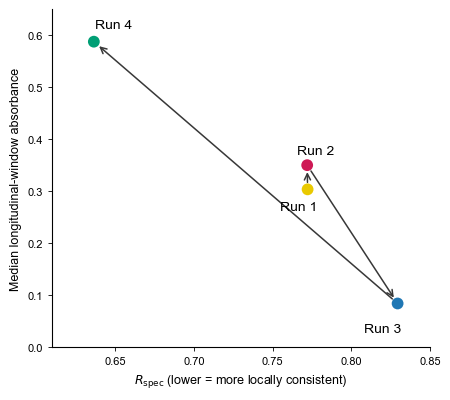

In [15]:
# Figure 3b: plot the four runs with the run labels, color palette,
# axis text, and arrows showing chronological progression: 1 -> 2 -> 3 -> 4.
# Values come only from roughness_summary, calculated from plate_spectra.xlsx.

FIG3B_RUNS = ["Run 1", "Run 2", "Run 3", "Run 4"]
FIG3B_COLORS = {
    "Run 1": "#E9C900",  # yellow
    "Run 2": "#CE1955",  # magenta
    "Run 3": "#1F77B4",  # blue
    "Run 4": "#009F75",  # green
}

fig3b, ax = plt.subplots(figsize=(4.5, 4.0))
fig3b.patch.set_facecolor("white")
ax.set_facecolor("white")

# Draw arrows before points so line segments sit behind the colored markers.
# The arrow direction reflects chronological order, not a causal trajectory.
for start, end in zip(FIG3B_RUNS[:-1], FIG3B_RUNS[1:]):
    p = roughness_summary.loc[start]
    q = roughness_summary.loc[end]
    ax.annotate(
        "",
        xy=(q["R_spec"], q["median_A_L"]),
        xytext=(p["R_spec"], p["median_A_L"]),
        arrowprops=dict(arrowstyle="->", color="#383838", lw=1.1,
                        shrinkA=5, shrinkB=5, mutation_scale=11),
        zorder=1,
    )

# Label offsets in points are configured for the Figure 3b layout.
FIG3B_LABEL_OFFSETS = {
    "Run 1": (-20, -13),
    "Run 2": (-7, 10),
    "Run 3": (-24, -19),
    "Run 4": (1, 12),
}
for name in FIG3B_RUNS:
    row = roughness_summary.loc[name]
    x_value = float(row["R_spec"])
    y_value = float(row["median_A_L"])
    ax.scatter(x_value, y_value, s=72, color=FIG3B_COLORS[name],
               edgecolors="none", zorder=4)
    ax.annotate(name, (x_value, y_value),
                xytext=FIG3B_LABEL_OFFSETS[name],
                textcoords="offset points", fontsize=10, color="black",
                ha="left", va="center", zorder=5)

ax.set_xlim(0.61, 0.85)
ax.set_ylim(0.0, 0.65)
ax.set_xticks(np.arange(0.65, 0.851, 0.05))
ax.set_yticks(np.arange(0.0, 0.651, 0.1))
ax.set_xlabel(r"$R_{\mathrm{spec}}$ (lower = more locally consistent)", fontsize=9)
ax.set_ylabel("Median longitudinal-window absorbance", fontsize=9)

# Keep the uncluttered style of the original: no grid, legend, or null line.
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", labelsize=8, width=0.6, length=3)
fig3b.tight_layout(pad=0.7)

fig3b.savefig("Figure3b_roughness_vs_signal.png", dpi=400)
fig3b.savefig("Figure3b_roughness_vs_signal.pdf")
plt.show()
